# 05 — Aprendizaje no supervisado: regímenes operativos de los pozos (clustering)

**4.ª pre-entrega · Clase 25.** Desarrollamos un modelo de clustering desde el análisis exploratorio (AED) hasta su revisión y ajuste final. Cada decisión queda registrada con su **criterio** y la **alternativa descartada**; la tabla final las reúne.

**Qué hacemos y por qué**

1. **AED y unidad de análisis.** Con solo cinco pozos, agrupar «un pozo» daría 5 observaciones: muy poco para elegir cuántos grupos hay. Por eso la unidad es **«un pozo durante 30 días»** (una ventana). Así hay cientos de observaciones y cada pozo puede pasar por distintos **regímenes** a lo largo de su vida.
2. **Variables** que describen cómo opera el pozo, sin repetir información.
3. **Elección del algoritmo y de K con reglas escritas**, comparando K-Means, jerárquico (Ward) y mezcla gaussiana.
4. **Revisión de calidad del resultado:** estabilidad (¿cambia si cambio la muestra?) y sensibilidad (¿depende de una sola variable?).
5. **Interpretación** de cada régimen con valores en unidades originales.
6. **Conexión con la pregunta del proyecto:** ¿el régimen del mes anterior ayuda a saber cuándo desconfiar de «dentro de 7 días, lo mismo que hoy»?

**Cuidados heredados del resto del proyecto.** Los cortes temporales son los de los notebooks 03/04 (validación desde 2014-08-30, prueba desde 2015-09-05): el escalado y el agrupamiento se ajustan **solo con entrenamiento**. Se excluyen los días marcados `REVISAR_*`. El clustering es **exploratorio**: describe, no demuestra causas ni recomienda intervenciones físicas.

## 0. Preparación y parámetros

Todos los parámetros están juntos para que cada decisión sea visible y se pueda cambiar y volver a ejecutar.

In [1]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kruskal
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

# ---- Parámetros del análisis (cada uno se justifica más abajo) ----
SEMILLA = 42
VENTANA_DIAS = 30            # tamaño de la ventana pozo-período
MIN_DIAS_DATO = 20           # mínimo de días con dato válido para describir una ventana
MIN_DIAS_OPERATIVOS = 10     # por debajo de esto, la ventana se considera «parada»
UMBRAL_CORRELACION = 0.85    # mismo umbral de revisión que el notebook 02 (|Spearman|)
K_MIN, K_MAX = 3, 6          # rango de K que se compara para elegir
PARTICION_MINIMA = 0.05      # un clúster debe tener al menos 5 % de las ventanas
CORTE_VALIDACION = pd.Timestamp("2014-08-30")   # igual que 03/04
CORTE_PRUEBA = pd.Timestamp("2015-09-05")       # igual que 03/04
HORIZONTE = 7                # días calendario, igual que 03/04
UMBRAL_CAIDA = 0.20          # caída ≥ 20 % respecto de hoy, igual que 03/04
POZO = "NPD_WELL_BORE_NAME"

# ---- Registro de decisiones: decisión → criterio → alternativa descartada ----
decisiones = []
def decidir(etapa, decision, criterio, descartado):
    decisiones.append({"Etapa": etapa, "Decisión": decision,
                       "Criterio": criterio, "Alternativa descartada": descartado})

# ---- Rutas y carga ----
ROOT = Path.cwd()
if not (ROOT / "data" / "processed").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "data" / "processed").is_dir(), "No se encuentra data/processed. Revise la carpeta de trabajo."

# Cortes y definición del objetivo: se toman de las reglas guardadas por el notebook 03, si existen
ruta_reglas = ROOT / "data" / "processed" / "reglas_modelos_7d.json"
if ruta_reglas.is_file():
    reglas_03 = json.loads(ruta_reglas.read_text(encoding="utf-8"))
    CORTE_VALIDACION = pd.Timestamp(reglas_03["inicio_validacion"])
    CORTE_PRUEBA = pd.Timestamp(reglas_03["inicio_prueba"])
    HORIZONTE = int(reglas_03.get("horizonte_dias", HORIZONTE))
    UMBRAL_CAIDA = float(reglas_03.get("umbral_caida", UMBRAL_CAIDA))
    print("Cortes tomados de reglas_modelos_7d.json (notebook 03).")
else:
    print("No se encontró reglas_modelos_7d.json: se usan los cortes por defecto de la celda anterior.")
print(f"Validación desde {CORTE_VALIDACION.date()} · prueba desde {CORTE_PRUEBA.date()} · horizonte {HORIZONTE} días · caída ≥ {UMBRAL_CAIDA:.0%}")

ruta_datos = ROOT / "data" / "processed" / "produccion_exclusiva_preparada.csv"
produccion = pd.read_csv(ruta_datos, parse_dates=["DATEPRD"])

necesarias = {"DATEPRD", POZO, "ON_STREAM_HRS", "AVG_WHP_P", "AVG_CHOKE_SIZE_P",
              "BORE_OIL_VOL", "BORE_GAS_VOL", "BORE_WAT_VOL"}
faltan = necesarias - set(produccion.columns)
assert not faltan, f"Faltan columnas en el CSV preparado: {faltan}"

# Nombres más cortos solo para leer mejor tablas y gráficos (siguen siendo únicos)
produccion[POZO] = produccion[POZO].astype(str).str.replace("15/9-", "", regex=False)
produccion = produccion.sort_values([POZO, "DATEPRD"]).reset_index(drop=True)
for c in ["ON_STREAM_HRS", "AVG_WHP_P", "AVG_CHOKE_SIZE_P", "BORE_OIL_VOL", "BORE_GAS_VOL", "BORE_WAT_VOL"]:
    produccion[c] = pd.to_numeric(produccion[c], errors="coerce")

# Mismas reglas de lectura que el notebook 03: el estrangulador solo vale si su unidad es «%»
# y un volumen negativo se trata como desconocido (no como cero).
if "AVG_CHOKE_UOM" in produccion.columns:
    produccion.loc[~produccion["AVG_CHOKE_UOM"].eq("%"), "AVG_CHOKE_SIZE_P"] = np.nan
n_negativos = 0
for c in ["BORE_OIL_VOL", "BORE_GAS_VOL", "BORE_WAT_VOL"]:
    neg = produccion[c] < 0
    n_negativos += int(neg.sum())
    produccion.loc[neg, c] = np.nan
print(f"Volúmenes negativos pasados a desconocido: {n_negativos}")

print(f"Filas: {len(produccion):,} · pozos: {produccion[POZO].nunique()} · "
      f"período: {produccion['DATEPRD'].min().date()} a {produccion['DATEPRD'].max().date()}")

Cortes tomados de reglas_modelos_7d.json (notebook 03).
Validación desde 2014-08-30 · prueba desde 2015-09-05 · horizonte 7 días · caída ≥ 20%
Volúmenes negativos pasados a desconocido: 4
Filas: 9,001 · pozos: 5 · período: 2008-02-12 a 2016-09-17


## 1. AED: días válidos y ventanas

**Qué días usamos.** Se excluyen los días marcados con `REVISAR_*` (petróleo negativo, petróleo con cero horas, tipo WI, horas dudosas) y los que no tienen horas o volúmenes conocidos. Es el mismo criterio de «apartar lo marcado» del notebook 03.

**Qué es una ventana.** Con solo cinco pozos, agrupar pozos enteros daría 5 observaciones, así que la unidad de análisis es «un pozo durante 30 días». Se cuentan bloques consecutivos de 30 días desde la primera fecha de cada pozo. Para cada bloque resumimos el comportamiento **solo con días operativos** (horas > 0), y medimos aparte cuánto estuvo parado.

In [2]:
cols_marca = [c for c in produccion.columns if c.startswith("REVISAR_")]
if cols_marca:
    marcado = produccion[cols_marca].isin([True, "True", "true", 1]).any(axis=1)
else:
    marcado = pd.Series(False, index=produccion.index)

conocido = produccion[["ON_STREAM_HRS", "BORE_OIL_VOL", "BORE_GAS_VOL", "BORE_WAT_VOL"]].notna().all(axis=1)
dias = produccion[~marcado & conocido].copy()

# Grilla de ventanas: bloques de 30 días desde la primera fecha de cada pozo (misma grilla para todo)
inicio_pozo = produccion.groupby(POZO)["DATEPRD"].min()
for df_ in (produccion, dias):
    df_["ventana"] = (df_["DATEPRD"] - df_[POZO].map(inicio_pozo)).dt.days // VENTANA_DIAS

print(f"Días totales: {len(produccion):,} · marcados REVISAR_*: {int(marcado.sum()):,} · "
      f"sin dato conocido: {int((~conocido & ~marcado).sum()):,} · días válidos usados: {len(dias):,}")

decidir("Calidad de datos",
        "Excluir días marcados REVISAR_* y días sin horas o volúmenes conocidos",
        "Es el mismo criterio de apartado del notebook 03; no se resuelve la interpretación de las marcas, solo se las deja fuera. Igual que en el 03, el estrangulador solo se usa si su unidad es «%» y los volúmenes negativos se tratan como desconocidos.",
        "Corregir o imputar los valores marcados")

Días totales: 9,001 · marcados REVISAR_*: 16 · sin dato conocido: 4 · días válidos usados: 8,981


In [3]:
def resumen_ventana(g):
    # Resume una ventana con sus días válidos. Devuelve un dict con las variables.
    n = len(g)
    op = g[g["ON_STREAM_HRS"] > 0]
    fila = {"n_dias": n, "n_operativos": len(op)}
    if n >= MIN_DIAS_DATO and len(op) >= MIN_DIAS_OPERATIVOS:
        oil, gas, wat = op["BORE_OIL_VOL"], op["BORE_GAS_VOL"], op["BORE_WAT_VOL"]
        m = oil.mean()
        dia = (op["DATEPRD"] - op["DATEPRD"].min()).dt.days.values
        pendiente = np.polyfit(dia, oil.values, 1)[0] if np.ptp(dia) > 0 else np.nan
        liquido = m + wat.mean()
        fila.update({
            "oil_media_op": m,                                              # Sm3/día, solo días operativos
            "oil_cv": oil.std() / m if m > 0 else np.nan,                   # irregularidad dentro de la ventana
            "corte_agua": wat.mean() / liquido if liquido > 0 else np.nan,  # agua / (agua + petróleo)
            "gor": gas.mean() / m if m > 0 else np.nan,                     # gas por unidad de petróleo
            "frac_parado": 1 - len(op) / n,                                 # proporción de días con 0 horas
            "tendencia_rel": pendiente * VENTANA_DIAS / m if m > 0 else np.nan,  # cambio relativo en la ventana
            "whp_media": op["AVG_WHP_P"].mean(),                            # presión de cabeza, días operativos
            "choke_media": op["AVG_CHOKE_SIZE_P"].mean(),                   # estrangulador, días operativos
        })
    return fila

FEATURES_CANDIDATAS = ["oil_media_op", "corte_agua", "gor", "oil_cv",
                       "frac_parado", "tendencia_rel", "whp_media", "choke_media"]

# Grilla completa (incluye ventanas sin ningún día válido)
grilla = produccion.groupby([POZO, "ventana"]).size().rename("n_filas").reset_index()
grilla["fecha_ini"] = grilla[POZO].map(inicio_pozo) + pd.to_timedelta(grilla["ventana"] * VENTANA_DIAS, unit="D")
grilla["fecha_fin"] = grilla["fecha_ini"] + pd.Timedelta(days=VENTANA_DIAS - 1)

resumenes = [{POZO: p, "ventana": v, **resumen_ventana(g)} for (p, v), g in dias.groupby([POZO, "ventana"])]
ventanas = grilla.merge(pd.DataFrame(resumenes), on=[POZO, "ventana"], how="left")
ventanas[["n_dias", "n_operativos"]] = ventanas[["n_dias", "n_operativos"]].fillna(0).astype(int)

def estado_ventana(r):
    if r["n_dias"] < MIN_DIAS_DATO:
        return "sin_cobertura"
    if r["n_operativos"] < MIN_DIAS_OPERATIVOS:
        return "parado"
    if r[FEATURES_CANDIDATAS].isna().any():
        return "incompleta"
    return "agrupable"

ventanas["estado"] = ventanas.apply(estado_ventana, axis=1)

def periodo_de(fecha):
    return np.where(fecha < CORTE_VALIDACION, "entrenamiento",
           np.where(fecha < CORTE_PRUEBA, "validación", "prueba"))

ventanas["periodo"] = periodo_de(ventanas["fecha_fin"])   # por fecha de FIN: una ventana de entrenamiento no ve el futuro del corte

print("Ventanas por pozo y estado:")
display(pd.crosstab(ventanas[POZO], ventanas["estado"], margins=True))
print("Ventanas agrupables por período:")
display(ventanas[ventanas["estado"] == "agrupable"]["periodo"].value_counts().rename("ventanas").to_frame())

Ventanas por pozo y estado:


estado,agrupable,parado,sin_cobertura,All
NPD_WELL_BORE_NAME,,,,
F-1 C,22,3,0,25
F-11,39,0,0,39
F-12,101,3,1,105
F-14,96,8,1,105
F-15 D,29,4,0,33
All,287,18,2,307


Ventanas agrupables por período:


,ventanas
periodo,
entrenamiento,173
validación,60
prueba,54


### Cómo se leen los estados

- **agrupable:** tiene suficientes días válidos y operativos; entra al clustering.
- **parado:** casi no operó en esos 30 días. Es un régimen conocido (no hace falta un algoritmo para detectarlo), así que se **etiqueta por regla** y se deja fuera del clustering para que no domine la distancia.
- **sin_cobertura / incompleta:** faltan días o variables; no se inventan valores (sin `fillna(0)`).

In [4]:
decidir("Unidad de análisis",
        f"Ventana de {VENTANA_DIAS} días por pozo; mínimo {MIN_DIAS_DATO} días válidos; «parada» si operó menos de {MIN_DIAS_OPERATIVOS} días",
        f"Con {ventanas[POZO].nunique()} pozos, agrupar pozos enteros daría {ventanas[POZO].nunique()} observaciones: insuficiente para elegir K con métricas. Un mes es lo bastante largo para que los promedios sean estables y lo bastante corto para ver cambios de régimen; los mínimos evitan describir ventanas casi vacías.",
        "Un punto por pozo con el promedio de toda su historia; ventanas de 7 o 90 días; imputar días faltantes")
decidir("Ventanas parado",
        "Etiquetar por regla las ventanas paradas y no incluirlas en el clustering",
        "«Parado» es conocido de antemano; incluirlo haría que el algoritmo gaste un grupo en lo obvio y distorsione la distancia al resto.",
        "Dejar que el algoritmo agrupe también las ventanas paradas")
decidir("Valores faltantes",
        "No imputar: las ventanas con variables faltantes quedan «incompleta»",
        "Se evita fabricar ceros (el README pide no convertir faltantes en ceros).",
        "fillna(0) o imputar por la media")

Ventanas agrupables de entrenamiento: 173


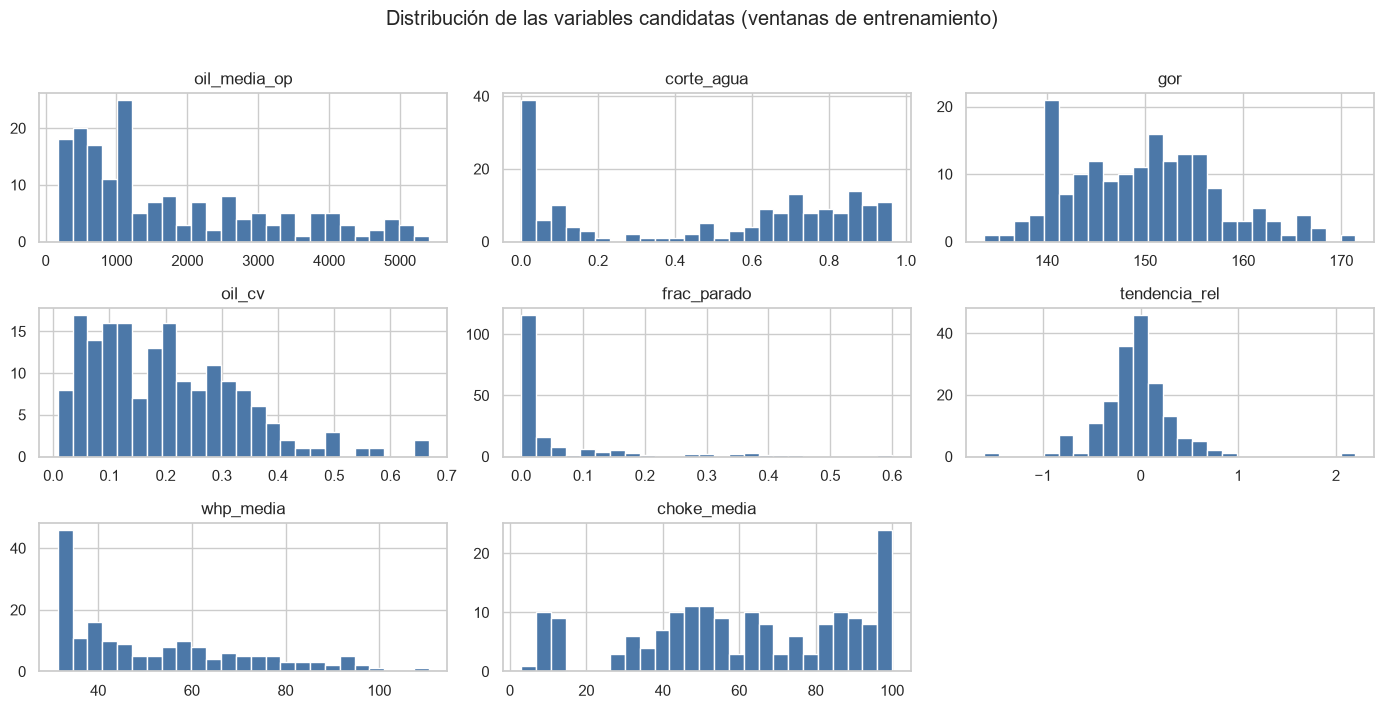

,count,mean,std,min,25%,50%,75%,max
oil_media_op,173.000,"1,754.779","1,389.385",171.346,668.633,"1,189.536","2,642.169","5,406.902"
corte_agua,173.000,0.488,0.360,0.000,0.061,0.630,0.804,0.964
gor,173.000,149.773,7.501,133.622,143.404,149.703,154.772,171.447
oil_cv,173.000,0.200,0.132,0.008,0.092,0.188,0.288,0.668
frac_parado,173.000,0.050,0.106,0.000,0.000,0.000,0.036,0.600
tendencia_rel,173.000,-0.045,0.371,-1.600,-0.214,-0.060,0.118,2.200
whp_media,173.000,51.869,19.310,31.367,34.129,45.396,63.910,110.581
choke_media,173.000,61.508,28.086,2.926,43.184,61.985,87.404,100.000


In [5]:
tr = ventanas[(ventanas["estado"] == "agrupable") & (ventanas["periodo"] == "entrenamiento")].copy()
print(f"Ventanas agrupables de entrenamiento: {len(tr)}")
assert len(tr) >= 30, "Hay muy pocas ventanas de entrenamiento: revise los parámetros de ventana/cobertura."

tr[FEATURES_CANDIDATAS].hist(bins=25, figsize=(14, 7), color="#4C78A8", edgecolor="white")
plt.suptitle("Distribución de las variables candidatas (ventanas de entrenamiento)", y=1.01)
plt.tight_layout(); plt.show()

display(tr[FEATURES_CANDIDATAS].describe().T)

### Qué miramos en los histogramas

Las variables de volumen (`oil_media_op`, `gor`) tienen cola larga a la derecha: unas pocas ventanas muy grandes dominarían la distancia. Y todas tienen valores extremos ocasionales. Por eso, en la preparación:

- se aplica **logaritmo** a `oil_media_op` y `gor`;
- se **recortan** los extremos al percentil 1 y 99 (calculados con entrenamiento);
- se **estandariza** (media 0, desvío 1), porque K-Means y Ward usan distancias.

## 2. Elección de variables: sin repetir información

Si dos variables dicen casi lo mismo, la distancia cuenta esa información dos veces. Aplicamos una **regla fija**: recorremos las candidatas en el orden de prioridad de la lista (de lo más interpretable a lo más técnico) y descartamos la que tenga |Spearman| ≥ 0,85 con una ya elegida. El umbral es el mismo que usamos para marcar relaciones entre entradas en el notebook 02. Spearman no cambia con el logaritmo.

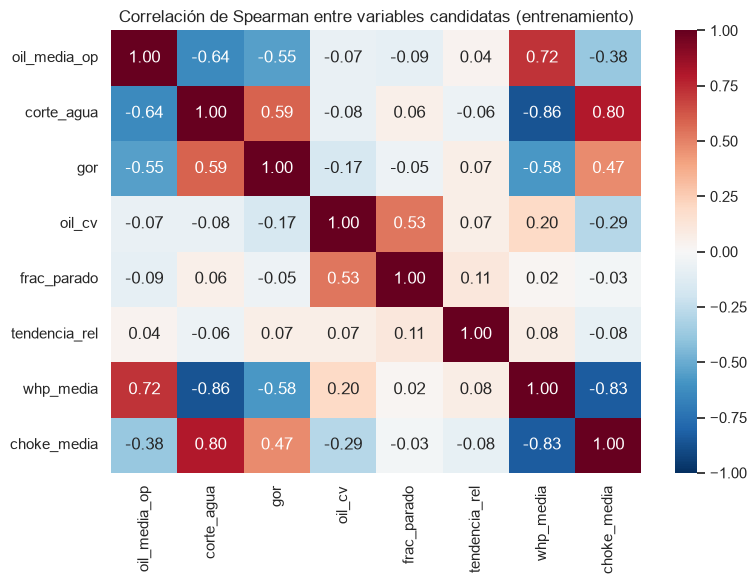

Variables conservadas: ['oil_media_op', 'corte_agua', 'gor', 'oil_cv', 'frac_parado', 'tendencia_rel', 'choke_media']
  Descartada: whp_media (|ρ| = 0.86 con corte_agua)


In [6]:
rho = tr[FEATURES_CANDIDATAS].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(rho, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlación de Spearman entre variables candidatas (entrenamiento)")
plt.tight_layout(); plt.show()

FEATURES, descartadas = [], []
for f in FEATURES_CANDIDATAS:
    choque = [g for g in FEATURES if abs(rho.loc[f, g]) >= UMBRAL_CORRELACION]
    if choque:
        descartadas.append((f, choque[0], rho.loc[f, choque[0]]))
    else:
        FEATURES.append(f)

print("Variables conservadas:", FEATURES)
for f, g, r in descartadas:
    print(f"  Descartada: {f} (|ρ| = {abs(r):.2f} con {g})")
assert len(FEATURES) >= 3, "Quedaron menos de 3 variables: revise el umbral o las candidatas."

decidir("Variables",
        f"Variables finales: {', '.join(FEATURES)}",
        f"Candidatas ordenadas por interpretabilidad; se descarta la que tiene |Spearman| ≥ {UMBRAL_CORRELACION} con una ya elegida."
        + (" Descartadas: " + "; ".join(f"{f} (≈{g})" for f, g, _ in descartadas) + "." if descartadas else " Ninguna se descartó."),
        "Usar todas las variables sin revisar redundancia")
decidir("Variables derivadas",
        "Describir cada ventana con producción, corte de agua, GOR, irregularidad, fracción parada, tendencia, presión y estrangulador; promedios solo sobre días operativos",
        "Cubren distintas dimensiones del régimen (nivel, agua/gas, estabilidad, disponibilidad, tendencia). Promediar días parados mezclaría «pozo chico» con «pozo detenido»; por eso la parada se mide aparte.",
        "Promedios simples de toda la ventana con días parados incluidos")

In [7]:
class Preparador:
    # Logaritmo + recorte de extremos + estandarización. Todo se aprende SOLO con entrenamiento.
    def __init__(self, columnas, log_cols=("oil_media_op", "gor")):
        self.columnas = list(columnas)
        self.log_cols = [c for c in log_cols if c in self.columnas]
    def _base(self, df):
        d = df[self.columnas].astype(float).copy()
        for c in self.log_cols:
            d[c] = np.log1p(d[c].clip(lower=0))
        return d
    def fit(self, df):
        d = self._base(df)
        self.lo, self.hi = d.quantile(0.01), d.quantile(0.99)
        self.escala = StandardScaler().fit(d.clip(lower=self.lo, upper=self.hi, axis=1))
        return self
    def transform(self, df):
        d = self._base(df).clip(lower=self.lo, upper=self.hi, axis=1)
        return self.escala.transform(d)

prep = Preparador(FEATURES).fit(tr)
X_tr = prep.transform(tr)
print("Matriz de entrenamiento:", X_tr.shape)

decidir("Preparación",
        "Logaritmo en volumen y GOR, recorte en percentiles 1–99 y estandarización, ajustados solo con entrenamiento",
        "Las colas largas dominan las distancias; K-Means y Ward usan distancia euclídea. Ajustar solo con entrenamiento evita filtrar validación/prueba.",
        "Escalar con todo el historial; no tratar valores extremos")

Matriz de entrenamiento: (173, 7)


## 3. Elección del algoritmo y de K con reglas escritas

Se comparan tres familias, con K de 2 a 6 (la tabla muestra también K = 2, pero la elección parte de K ≥ 3):

| Algoritmo | Idea | Cuándo conviene |
|---|---|---|
| **K-Means** | Grupos compactos alrededor de un centro | Grupos de tamaño parecido y forma redondeada |
| **Jerárquico (Ward)** | Va uniendo los más parecidos | Pocos datos, estructura anidada; permite dendrograma |
| **Mezcla gaussiana** | Cada grupo es una «campana» con su propia dispersión | Grupos de distinta dispersión; da pertenencia suave |

**Métricas (se miran las tres):**
- **Silueta** (↑ mejor): qué tan separada y compacta es cada observación respecto de su grupo.
- **Davies-Bouldin** (↓ mejor): cuánto se parecen entre sí los grupos.
- **Calinski-Harabasz** (↑ mejor): cociente entre dispersión entre grupos y dentro de grupos.

**Regla de elección (escrita antes de ver resultados):**
1. Se consideran solo combinaciones con **K ≥ 3** y con **ningún clúster menor al 5 %** de las ventanas.
2. Entre ellas, se elige la de **mayor silueta**.
3. K = 2 se muestra pero no se elige. Típicamente separa «grande» de «chico», cosa que ya sabemos, y no ayuda a describir regímenes.

,algoritmo,K,silueta,davies_bouldin,calinski_harabasz,clúster_menor_%,tamaños
0,K-Means,2,0.305,1.371,77.340,47.977,"[90, 83]"
1,K-Means,3,0.321,1.190,68.425,10.983,"[19, 81, 73]"
2,K-Means,4,0.314,1.275,61.981,10.983,"[19, 24, 75, 55]"
3,K-Means,5,0.271,1.381,56.746,10.405,"[31, 52, 49, 18, 23]"
4,K-Means,6,0.272,1.449,53.656,5.780,"[47, 33, 45, 14, 24, 10]"
5,Jerárquico (Ward),2,0.278,1.488,65.000,47.977,"[90, 83]"
6,Jerárquico (Ward),3,0.309,1.168,59.710,4.624,"[83, 82, 8]"
7,Jerárquico (Ward),4,0.282,1.547,51.686,4.624,"[36, 82, 8, 47]"
8,Jerárquico (Ward),5,0.290,1.352,48.830,4.624,"[82, 16, 8, 47, 20]"
9,Jerárquico (Ward),6,0.236,1.435,48.374,4.624,"[46, 16, 36, 47, 20, 8]"


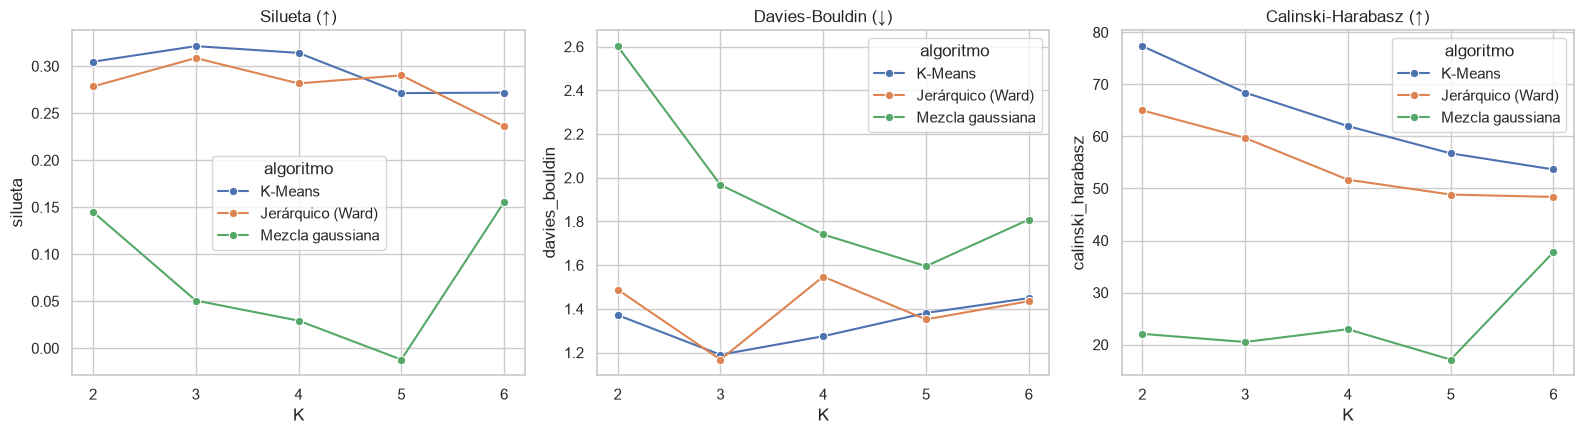

In [8]:
def construir(nombre, k, semilla=SEMILLA):
    if nombre == "K-Means":
        return KMeans(n_clusters=k, n_init=20, random_state=semilla)
    if nombre == "Jerárquico (Ward)":
        return AgglomerativeClustering(n_clusters=k, linkage="ward")
    if nombre == "Mezcla gaussiana":
        return GaussianMixture(n_components=k, covariance_type="diag", n_init=5, random_state=semilla)
    raise ValueError(nombre)

ALGORITMOS = ["K-Means", "Jerárquico (Ward)", "Mezcla gaussiana"]
filas = []
for nombre in ALGORITMOS:
    for k in range(2, K_MAX + 1):
        try:
            et = construir(nombre, k).fit_predict(X_tr)
        except Exception as e:
            print(f"No se pudo ajustar {nombre} con K={k}: {e}")
            continue
        if len(np.unique(et)) < 2:
            continue
        tam = np.bincount(et) / len(et)
        filas.append({"algoritmo": nombre, "K": k,
                      "silueta": silhouette_score(X_tr, et),
                      "davies_bouldin": davies_bouldin_score(X_tr, et),
                      "calinski_harabasz": calinski_harabasz_score(X_tr, et),
                      "clúster_menor_%": tam[tam > 0].min() * 100,
                      "tamaños": np.bincount(et).tolist()})
comparacion = pd.DataFrame(filas)
display(comparacion.round(3))

fig, ejes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col, titulo in zip(ejes, ["silueta", "davies_bouldin", "calinski_harabasz"],
                           ["Silueta (↑)", "Davies-Bouldin (↓)", "Calinski-Harabasz (↑)"]):
    sns.lineplot(data=comparacion, x="K", y=col, hue="algoritmo", marker="o", ax=ax)
    ax.set_title(titulo)
    ax.set_xticks(range(2, K_MAX + 1))
plt.tight_layout(); plt.show()

In [9]:
elegibles = comparacion[(comparacion["K"] >= K_MIN) & (comparacion["clúster_menor_%"] >= PARTICION_MINIMA * 100)]
if elegibles.empty:
    print("Ninguna combinación cumple el tamaño mínimo; se relaja esa condición (queda documentado).")
    elegibles = comparacion[comparacion["K"] >= K_MIN]
mejor = elegibles.sort_values("silueta", ascending=False).iloc[0]
ALGORITMO, K = mejor["algoritmo"], int(mejor["K"])

print(f"Elegido por la regla: {ALGORITMO}, K = {K} "
      f"(silueta {mejor['silueta']:.3f}, Davies-Bouldin {mejor['davies_bouldin']:.3f}, "
      f"clúster menor {mejor['clúster_menor_%']:.1f} %)")
ordenados = elegibles.sort_values("silueta", ascending=False)
display(ordenados.head(5).round(3))
dif = np.nan
if len(ordenados) > 1:
    segundo = ordenados.iloc[1]
    dif = mejor["silueta"] - segundo["silueta"]
    print(f"Segunda opción: {segundo['algoritmo']}, K = {int(segundo['K'])} (silueta {segundo['silueta']:.3f}); diferencia {dif:.3f}.")
    if dif < 0.02:
        print("La diferencia es muy chica: las dos opciones son prácticamente equivalentes. "
              "La regla desempata, pero conviene decirlo al presentar.")

decidir("Algoritmo y K",
        f"{ALGORITMO} con K = {K}",
        f"Regla fijada de antemano: K ≥ {K_MIN}, clúster menor ≥ {PARTICION_MINIMA:.0%}, mayor silueta. Resultado: silueta {mejor['silueta']:.2f}."
        + (f" Diferencia con la segunda opción: {dif:.3f}." if not np.isnan(dif) else ""),
        "K = 2 (solo separa grande/chico); K elegido a ojo; DBSCAN (requiere elegir un radio y deja ventanas sin grupo, difícil de justificar con pocos datos)")

Elegido por la regla: K-Means, K = 3 (silueta 0.321, Davies-Bouldin 1.190, clúster menor 11.0 %)


,algoritmo,K,silueta,davies_bouldin,calinski_harabasz,clúster_menor_%,tamaños
1,K-Means,3,0.321,1.190,68.425,10.983,"[19, 81, 73]"
2,K-Means,4,0.314,1.275,61.981,10.983,"[19, 24, 75, 55]"
4,K-Means,6,0.272,1.449,53.656,5.780,"[47, 33, 45, 14, 24, 10]"
3,K-Means,5,0.271,1.381,56.746,10.405,"[31, 52, 49, 18, 23]"
14,Mezcla gaussiana,6,0.155,1.808,37.766,7.514,"[23, 13, 38, 18, 60, 21]"


Segunda opción: K-Means, K = 4 (silueta 0.314); diferencia 0.007.
La diferencia es muy chica: las dos opciones son prácticamente equivalentes. La regla desempata, pero conviene decirlo al presentar.


### Cómo leer la silueta

Valores cercanos a 1: grupos bien separados. Cerca de 0: los grupos se tocan. Negativos: observaciones que parecen estar en el grupo equivocado. En datos reales de operación, una silueta de **0,25–0,50** suele indicar estructura moderada: los regímenes se mezclan en los bordes porque un pozo **cambia gradualmente** de un estado a otro. No es un defecto; hay que decirlo al interpretar.

## 4. Revisión de la calidad del resultado

Un clustering siempre devuelve grupos, aunque no existan. Por eso se prueban dos cosas antes de interpretar:

- **Estabilidad:** si repito el ajuste con el 80 % de las ventanas elegidas al azar y comparo con el agrupamiento de referencia (el ajustado con todo el entrenamiento), ¿se parecen? Se mide con el **índice de Rand ajustado (ARI)**: 1 = idénticos, 0 = tan parecidos como el azar.
- **Sensibilidad:** si quito una variable, ¿cambia mucho el agrupamiento? Si cambia radicalmente, esa variable decide casi todo.

Estabilidad (ARI con 80 % de la muestra, 40 repeticiones): media 0.84 · mínimo 0.54 · máximo 0.90
Lectura: estable (≥ 0,7 estable · 0,5–0,7 moderada · < 0,5 inestable)


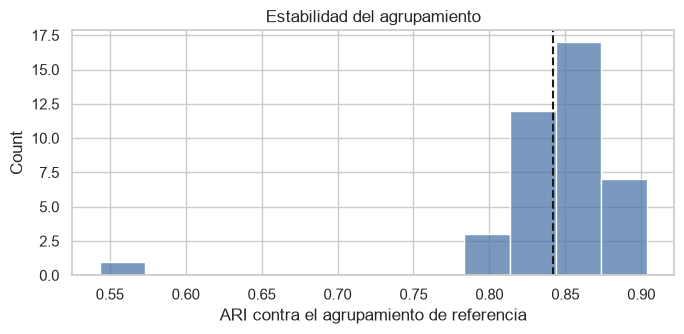

In [10]:
ref = construir(ALGORITMO, K).fit_predict(X_tr)

def estabilidad(X, ref, reps=40, frac=0.8):
    rng = np.random.default_rng(SEMILLA)
    aris = []
    for r in range(reps):
        idx = rng.choice(len(X), int(frac * len(X)), replace=False)
        et_sub = construir(ALGORITMO, K, semilla=r).fit_predict(X[idx])
        # las ventanas no usadas se asignan al grupo de sus vecinos más cercanos
        completo = KNeighborsClassifier(n_neighbors=5).fit(X[idx], et_sub).predict(X)
        aris.append(adjusted_rand_score(ref, completo))
    return np.array(aris)

aris = estabilidad(X_tr, ref)
print(f"Estabilidad (ARI con 80 % de la muestra, 40 repeticiones): media {aris.mean():.2f} · mínimo {aris.min():.2f} · máximo {aris.max():.2f}")
if aris.mean() >= 0.7:
    veredicto = "estable"
elif aris.mean() >= 0.5:
    veredicto = "moderadamente estable"
else:
    veredicto = "inestable"
print("Lectura:", veredicto, "(≥ 0,7 estable · 0,5–0,7 moderada · < 0,5 inestable)")

plt.figure(figsize=(7, 3.5))
sns.histplot(aris, bins=12, color="#4C78A8")
plt.axvline(aris.mean(), color="k", linestyle="--")
plt.xlabel("ARI contra el agrupamiento de referencia"); plt.title("Estabilidad del agrupamiento")
plt.tight_layout(); plt.show()

In [11]:
filas = []
for j, f in enumerate(FEATURES):
    cols = [i for i in range(len(FEATURES)) if i != j]
    et_sin = construir(ALGORITMO, K).fit_predict(X_tr[:, cols])
    filas.append({"variable quitada": f, "ARI vs. agrupamiento completo": adjusted_rand_score(ref, et_sin)})
sensibilidad = pd.DataFrame(filas).sort_values("ARI vs. agrupamiento completo")
display(sensibilidad.round(3))
variable_clave = sensibilidad.iloc[0]["variable quitada"]
print(f"La variable que más cambia el resultado al quitarla es «{variable_clave}».")

decidir("Revisión",
        f"Estabilidad {veredicto} (ARI medio {aris.mean():.2f}); variable más influyente: {variable_clave}",
        "ARI con submuestras del 80 % (40 repeticiones) y quitando una variable por vez.",
        "Aceptar el agrupamiento sin probar si cambia al variar la muestra")

,variable quitada,ARI vs. agrupamiento completo
4,frac_parado,0.757
6,choke_media,0.812
1,corte_agua,0.845
3,oil_cv,0.874
0,oil_media_op,0.897
5,tendencia_rel,0.939
2,gor,0.959


La variable que más cambia el resultado al quitarla es «frac_parado».


### Qué hacer con estos resultados

- **ARI alto y sin una variable que lo decida todo:** los regímenes son un resumen razonable.
- **ARI bajo o una variable dominante:** los grupos dependen de la muestra o de una sola medida; hay que presentarlos como descripción, no como categorías firmes, y mencionarlo en las limitaciones.

## 5. Modelo final y asignación de todas las ventanas

El modelo se ajusta con entrenamiento y luego **asigna** regímenes a las ventanas de validación y prueba (sin reajustar). El algoritmo jerárquico no tiene `predict`: en ese caso la asignación se hace con el grupo de los 5 vecinos más cercanos de entrenamiento. Los números de clúster se reordenan de menor a mayor producción mediana para que sean legibles.

In [12]:
class ModeloRegimenes:
    def __init__(self, algoritmo, k):
        self.modelo = construir(algoritmo, k)
    def fit(self, X):
        self.etiquetas_ = self.modelo.fit_predict(X)
        self._knn = None if hasattr(self.modelo, "predict") else KNeighborsClassifier(5).fit(X, self.etiquetas_)
        return self
    def predict(self, X):
        return self.modelo.predict(X) if self._knn is None else self._knn.predict(X)

final = ModeloRegimenes(ALGORITMO, K).fit(X_tr)

# Reordenar los números de clúster por producción mediana de entrenamiento
orden = tr.assign(c=final.etiquetas_).groupby("c")["oil_media_op"].median().sort_values().index
mapa = {viejo: nuevo for nuevo, viejo in enumerate(orden)}

agrup = ventanas["estado"] == "agrupable"
X_all = prep.transform(ventanas.loc[agrup])
ventanas["cluster"] = np.nan
ventanas.loc[agrup, "cluster"] = pd.Series(final.predict(X_all), index=ventanas.index[agrup]).map(mapa)
tr["cluster"] = pd.Series(final.etiquetas_, index=tr.index).map(mapa)
X_tr_df = pd.DataFrame(X_tr, columns=FEATURES, index=tr.index)

print("Ventanas por clúster y período:")
display(pd.crosstab(ventanas["cluster"], ventanas["periodo"], margins=True))

Ventanas por clúster y período:


periodo,entrenamiento,prueba,validación,All
cluster,,,,
0.000,73,35,23,131
1.000,19,15,12,46
2.000,81,4,25,110
All,173,54,60,287


## 6. Interpretación de cada régimen

Tres vistas complementarias: **valores reales** (mediana en unidades originales), **centroides estandarizados** (qué variables distinguen a cada grupo) y **mapa PCA** (cómo se reparten las ventanas).

Mediana por régimen, en unidades originales (todas las ventanas agrupables):


,ventanas,% del total,oil_media_op,corte_agua,gor,oil_cv,frac_parado,tendencia_rel,choke_media
cluster,,,,,,,,,
0.000,131,45.645,492.190,0.845,155.073,0.101,0.000,-0.071,94.383
1.000,46,16.028,351.944,0.691,152.689,0.336,0.379,0.288,53.209
2.000,110,38.328,"2,095.924",0.100,145.730,0.169,0.000,-0.060,34.194


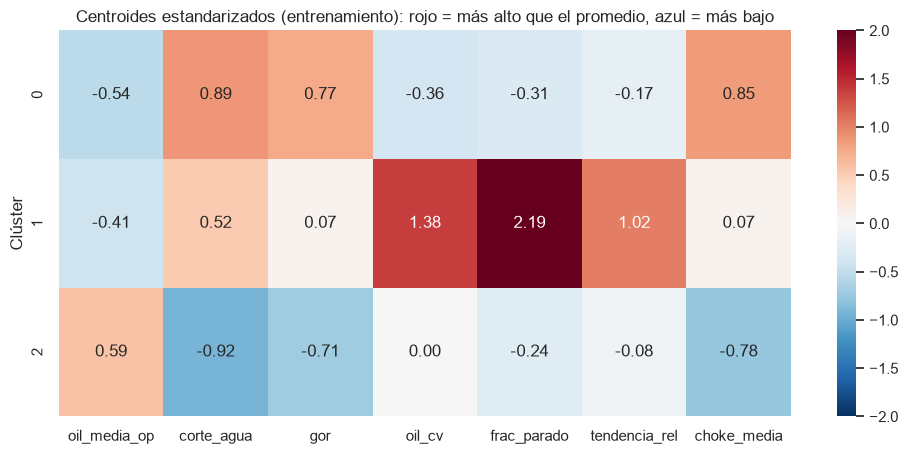

Rasgos que más distinguen a cada régimen (|z| ≥ 0,7):
  Clúster 0 → altos: corte_agua (+0.9), gor (+0.8), choke_media (+0.8) | bajos: —
  Clúster 1 → altos: oil_cv (+1.4), frac_parado (+2.2), tendencia_rel (+1.0) | bajos: —
  Clúster 2 → altos: — | bajos: corte_agua (-0.9), gor (-0.7), choke_media (-0.8)


In [13]:
orig = ["oil_media_op", "corte_agua", "gor", "oil_cv", "frac_parado", "tendencia_rel", "whp_media", "choke_media"]
orig = [c for c in orig if c in FEATURES]

perfil = ventanas[agrup].groupby("cluster")[orig].median()
perfil.insert(0, "ventanas", ventanas[agrup].groupby("cluster").size())
perfil.insert(1, "% del total", 100 * perfil["ventanas"] / perfil["ventanas"].sum())
print("Mediana por régimen, en unidades originales (todas las ventanas agrupables):")
display(perfil)

centroides = X_tr_df.groupby(tr["cluster"]).mean()
fig, ax = plt.subplots(figsize=(10, 0.9 * K + 2))
sns.heatmap(centroides, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-2, vmax=2, ax=ax)
ax.set_ylabel("Clúster"); ax.set_title("Centroides estandarizados (entrenamiento): rojo = más alto que el promedio, azul = más bajo")
plt.tight_layout(); plt.show()

print("Rasgos que más distinguen a cada régimen (|z| ≥ 0,7):")
for c, fila in centroides.iterrows():
    altos = [f"{f} (+{v:.1f})" for f, v in fila.items() if v >= 0.7]
    bajos = [f"{f} ({v:.1f})" for f, v in fila.items() if v <= -0.7]
    print(f"  Clúster {int(c)} → altos: {', '.join(altos) or '—'} | bajos: {', '.join(bajos) or '—'}")

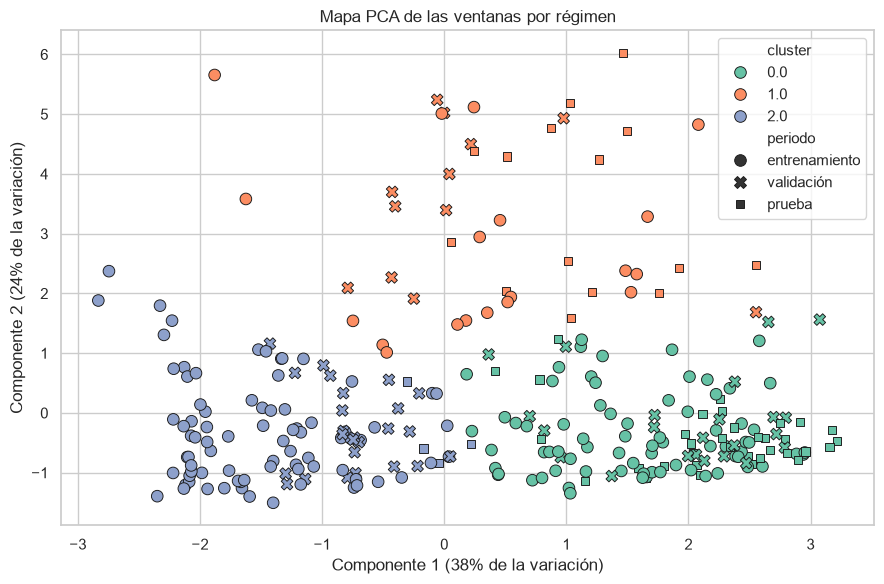

Qué variables forman cada eje (cargas):


,PC1,PC2
oil_media_op,-0.425,-0.198
corte_agua,0.571,0.058
gor,0.485,0.045
oil_cv,-0.116,0.626
frac_parado,-0.017,0.642
tendencia_rel,-0.035,0.381
choke_media,0.492,-0.085


In [14]:
pca = PCA(n_components=2, random_state=SEMILLA).fit(X_tr)
Z = pca.transform(X_all)
graf = ventanas.loc[agrup, ["cluster", "periodo", POZO]].copy()
graf["PC1"], graf["PC2"] = Z[:, 0], Z[:, 1]

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=graf, x="PC1", y="PC2", hue="cluster", style="periodo",
                palette="Set2", s=70, edgecolor="k", ax=ax)
ax.set_xlabel(f"Componente 1 ({pca.explained_variance_ratio_[0]:.0%} de la variación)")
ax.set_ylabel(f"Componente 2 ({pca.explained_variance_ratio_[1]:.0%} de la variación)")
ax.set_title("Mapa PCA de las ventanas por régimen")
plt.tight_layout(); plt.show()

cargas = pd.DataFrame(pca.components_.T, index=FEATURES, columns=["PC1", "PC2"])
print("Qué variables forman cada eje (cargas):")
display(cargas)

### Poner nombre a los regímenes

Mire la tabla de medianas, el heatmap y las líneas de «rasgos»: describen **cómo operan** las ventanas de cada grupo. Complete el diccionario con un nombre breve basado en esa evidencia (por ejemplo, «producción alta y estable» o «producción baja con mucha agua»). Mientras no lo edite, se usa «Régimen k». Los nombres no cambian ningún cálculo, solo las etiquetas de los gráficos y tablas.

In [15]:
# EDITAR después de leer la tabla de medianas, el heatmap y los rasgos de arriba.
# Ejemplo de formato: {0: "Producción baja", 1: "Producción media con agua", 2: "Producción alta estable"}
NOMBRES = {}

def nombre_regimen(r):
    if r["estado"] == "agrupable":
        c = int(r["cluster"])
        return NOMBRES.get(c, f"Régimen {c}")
    if r["estado"] == "parado":
        return "Parado (regla)"
    return "Sin datos suficientes"

ventanas["regimen"] = ventanas.apply(nombre_regimen, axis=1)
nombres_cluster = [NOMBRES.get(c, f"Régimen {c}") for c in range(K)]
paleta = dict(zip(nombres_cluster, sns.color_palette("Set2", K)))
paleta["Parado (regla)"] = "#333333"
paleta["Sin datos suficientes"] = "#BBBBBB"

Porcentaje de ventanas de cada pozo en cada régimen:


regimen,Parado (regla),Régimen 0,Régimen 1,Régimen 2,Sin datos suficientes
NPD_WELL_BORE_NAME,,,,,
F-1 C,12.000,12.000,64.000,12.000,0.000
F-11,0.000,28.200,5.100,66.700,0.000
F-12,2.900,49.500,11.400,35.200,1.000
F-14,7.600,58.100,7.600,25.700,1.000
F-15 D,12.100,12.100,24.200,51.500,0.000


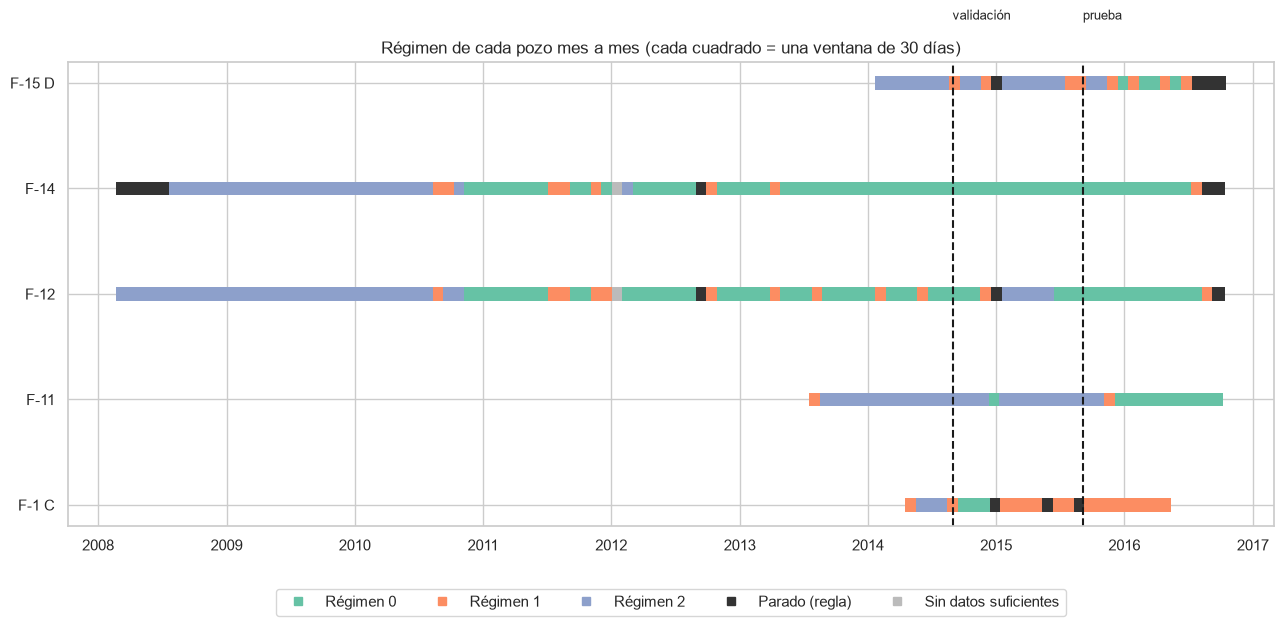

In [16]:
# Composición por pozo y evolución en el tiempo
comp = pd.crosstab(ventanas[POZO], ventanas["regimen"], normalize="index") * 100
print("Porcentaje de ventanas de cada pozo en cada régimen:")
display(comp.round(1))

pozos = sorted(ventanas[POZO].unique())
fig, ax = plt.subplots(figsize=(13, 0.9 * len(pozos) + 2))
for i, p in enumerate(pozos):
    sub = ventanas[ventanas[POZO] == p]
    ax.scatter(sub["fecha_fin"], [i] * len(sub), c=[paleta[r] for r in sub["regimen"]],
               s=90, marker="s", edgecolor="none")
ax.set_yticks(range(len(pozos))); ax.set_yticklabels(pozos)
for corte, txt in [(CORTE_VALIDACION, "validación"), (CORTE_PRUEBA, "prueba")]:
    ax.axvline(corte, color="k", linestyle="--"); ax.text(corte, len(pozos) - 0.4, txt, ha="left", fontsize=9)
handles = [plt.Line2D([0], [0], marker="s", linestyle="", color=c, label=n) for n, c in paleta.items()]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=min(len(handles), 5))
ax.set_title("Régimen de cada pozo mes a mes (cada cuadrado = una ventana de 30 días)")
plt.tight_layout(); plt.show()

## 7. Conexión con el proyecto: ¿el régimen ayuda a saber cuándo desconfiar del pronóstico?

La pregunta del proyecto es si podemos reconocer de antemano cuándo conviene desconfiar del pronóstico. La referencia más simple, «dentro de siete días, lo mismo que hoy», ganó en regresión. Aquí revisamos **dónde falla**, según el régimen del pozo.

**Sin trampa temporal:** a cada día t se le asigna el régimen de la **ventana anterior completa** (ya terminada y conocida al cierre de t), no el de la ventana que lo contiene, que incluiría días futuros. Se usan los mismos criterios del 03: petróleo(t) > 0, petróleo(t+7) conocido y no negativo, sin días marcados, y se aparta cualquier par cuya respuesta caiga en el período siguiente.

Se miden dos cosas por régimen: el **error de la referencia** (MAE y error relativo mediano) y la **frecuencia de caídas ≥ 20 %**.

In [17]:
d = dias[[POZO, "DATEPRD", "ventana", "BORE_OIL_VOL"]].rename(columns={"BORE_OIL_VOL": "oil_t"})
fut = d[[POZO, "DATEPRD", "oil_t"]].rename(columns={"oil_t": "oil_t7"})
fut["DATEPRD"] = fut["DATEPRD"] - pd.Timedelta(days=HORIZONTE)         # el valor de t+7 se alinea con t

pares = d.merge(fut, on=[POZO, "DATEPRD"], how="inner")
pares = pares[(pares["oil_t"] > 0) & (pares["oil_t7"] >= 0)].copy()
pares["periodo"] = periodo_de(pares["DATEPRD"])
pares["periodo_t7"] = periodo_de(pares["DATEPRD"] + pd.Timedelta(days=HORIZONTE))
pares = pares[pares["periodo"] == pares["periodo_t7"]]                 # separar respuestas futuras

# Régimen de la ventana anterior (ya terminada al cierre de t)
previa = ventanas[[POZO, "ventana", "regimen"]].copy()
previa["ventana"] = previa["ventana"] + 1                              # la ventana v pasa a ser «la anterior» de v+1
pares = pares.merge(previa, on=[POZO, "ventana"], how="inner")

pares["error_abs"] = (pares["oil_t7"] - pares["oil_t"]).abs()          # referencia: mismo valor que hoy
pares["error_rel"] = pares["error_abs"] / pares["oil_t"]
pares["caida"] = (pares["oil_t"] - pares["oil_t7"]) / pares["oil_t"] >= UMBRAL_CAIDA

print(f"Pares día→día+{HORIZONTE} analizados: {len(pares):,}")
display(pares["periodo"].value_counts().rename("pares").to_frame())

decidir("Conexión con el proyecto",
        "Asignar a cada día el régimen de la ventana anterior completa",
        "La ventana que contiene el día incluye datos posteriores al cierre de t; la anterior ya terminó, así que el régimen es conocible al emitir el pronóstico.",
        "Usar el clúster de la ventana que contiene al día (filtraría información futura)")

Pares día→día+7 analizados: 7,605


,pares
periodo,
entrenamiento,4686
validación,1528
prueba,1391


In [18]:
def tabla_por_regimen(df):
    t = df.groupby("regimen").agg(
        pares=("error_abs", "size"),
        MAE=("error_abs", "mean"),
        error_relativo_mediano=("error_rel", "median"),
        tasa_caida_20=("caida", "mean"),
        caidas=("caida", "sum"),
    )
    t.loc["TODOS"] = [len(df), df["error_abs"].mean(), df["error_rel"].median(), df["caida"].mean(), df["caida"].sum()]
    t["tasa_caida_20"] *= 100
    t["pocos_datos"] = np.where(t["pares"] < 30, "⚠ <30", "")
    return t

fuera = pares[pares["periodo"].isin(["validación", "prueba"])]
dentro = pares[pares["periodo"] == "entrenamiento"]

print("FUERA DE MUESTRA (validación + prueba): el agrupamiento no vio estos días al ajustarse")
tabla_fuera = tabla_por_regimen(fuera)
display(tabla_fuera)
print("EN MUESTRA (entrenamiento): referencia para comparar")
display(tabla_por_regimen(dentro))

FUERA DE MUESTRA (validación + prueba): el agrupamiento no vio estos días al ajustarse


,pares,MAE,error_relativo_mediano,tasa_caida_20,caidas,pocos_datos
regimen,,,,,,
Parado (regla),116.000,179.837,0.252,36.207,42.000,
Régimen 0,"1,583.000",33.806,0.045,8.086,128.000,
Régimen 1,400.000,134.399,0.163,27.500,110.000,
Régimen 2,820.000,102.904,0.041,9.390,77.000,
TODOS,"2,919.000",72.805,0.051,12.230,357.000,


EN MUESTRA (entrenamiento): referencia para comparar


,pares,MAE,error_relativo_mediano,tasa_caida_20,caidas,pocos_datos
regimen,,,,,,
Parado (regla),50.000,665.924,0.265,14.000,7.000,
Régimen 0,"1,835.000",121.464,0.041,12.916,237.000,
Régimen 1,493.000,229.654,0.057,13.185,65.000,
Régimen 2,"2,250.000",544.126,0.080,15.689,353.000,
Sin datos suficientes,58.000,233.663,0.045,15.517,9.000,
TODOS,"4,686.000",342.987,0.061,14.319,671.000,


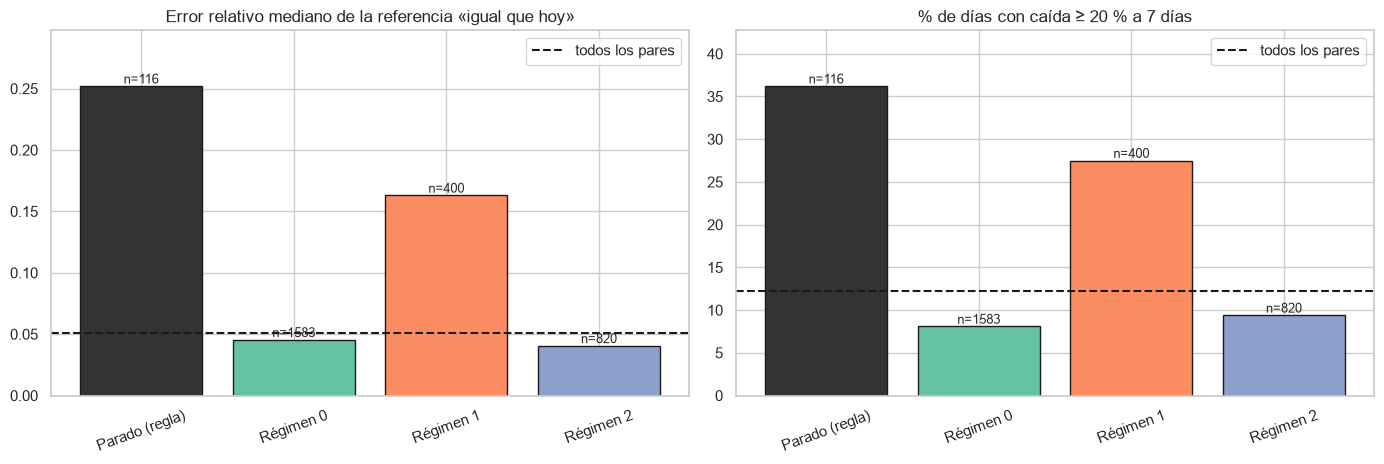

Prueba de Kruskal-Wallis sobre el error relativo (regímenes con ≥30 pares): H = 280.5, p = 1.7e-60
Cuidado: los días consecutivos de un mismo pozo no son independientes, así que este p-valor es solo orientativo; lo importante es el tamaño de las diferencias en la tabla.


In [19]:
t = tabla_fuera.drop(index="TODOS")
t = t.sort_index()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, col, titulo in [(a1, "error_relativo_mediano", "Error relativo mediano de la referencia «igual que hoy»"),
                        (a2, "tasa_caida_20", "% de días con caída ≥ 20 % a 7 días")]:
    colores = [paleta.get(i, "#999999") for i in t.index]
    ax.bar(t.index, t[col], color=colores, edgecolor="k")
    ax.axhline(tabla_fuera.loc["TODOS", col], color="k", linestyle="--", label="todos los pares")
    for x, (v, n) in enumerate(zip(t[col], t["pares"])):
        ax.text(x, v, f"n={int(n)}", ha="center", va="bottom", fontsize=9)
    ax.set_ylim(0, t[col].max() * 1.18)
    ax.set_title(titulo); ax.legend(); ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

grupos = [g["error_rel"].values for _, g in fuera.groupby("regimen") if len(g) >= 30]
if len(grupos) >= 2:
    h, p = kruskal(*grupos)
    print(f"Prueba de Kruskal-Wallis sobre el error relativo (regímenes con ≥30 pares): H = {h:.1f}, p = {p:.2g}")
    print("Cuidado: los días consecutivos de un mismo pozo no son independientes, así que este p-valor "
          "es solo orientativo; lo importante es el tamaño de las diferencias en la tabla.")

### Revisión de robustez del cruce

Antes de creer una diferencia, dos controles:

1. **¿Se repite en entrenamiento?** Si un régimen parece «riesgoso» solo fuera de muestra, la diferencia puede ser casualidad o depender de un período particular.
2. **¿Está concentrada en un pozo?** Con solo cinco pozos, un régimen puede ser en la práctica «el pozo X en su etapa final». Entonces el régimen no aporta más que saber qué pozo es.

In [20]:
cols = ["pares", "error_relativo_mediano", "tasa_caida_20"]
robustez = (tabla_por_regimen(dentro)[cols]
            .join(tabla_fuera[cols], lsuffix=" (entrenamiento)", rsuffix=" (fuera de muestra)", how="outer"))
print("Mismo indicador, en muestra frente a fuera de muestra:")
display(robustez)

conteo = pd.crosstab(fuera["regimen"], fuera[POZO])
print("Pares fuera de muestra por régimen y pozo (cantidad):")
display(conteo)
print("Cómo se reparte cada régimen entre pozos (% de sus pares fuera de muestra):")
display((conteo.div(conteo.sum(axis=1), axis=0) * 100).round(1))

Mismo indicador, en muestra frente a fuera de muestra:


,pares (entrenamiento),error_relativo_mediano (entrenamiento),tasa_caida_20 (entrenamiento),pares (fuera de muestra),error_relativo_mediano (fuera de muestra),tasa_caida_20 (fuera de muestra)
regimen,,,,,,
Parado (regla),50.000,0.265,14.000,116.000,0.252,36.207
Régimen 0,"1,835.000",0.041,12.916,"1,583.000",0.045,8.086
Régimen 1,493.000,0.057,13.185,400.000,0.163,27.500
Régimen 2,"2,250.000",0.080,15.689,820.000,0.041,9.390
Sin datos suficientes,58.000,0.045,15.517,NaN,NaN,NaN
TODOS,"4,686.000",0.061,14.319,"2,919.000",0.051,12.230


Pares fuera de muestra por régimen y pozo (cantidad):


NPD_WELL_BORE_NAME,F-1 C,F-11,F-12,F-14,F-15 D
regimen,,,,,
Parado (regla),56,0,30,0,30
Régimen 0,52,286,483,673,89
Régimen 1,199,30,5,0,166
Régimen 2,1,406,148,0,265


Cómo se reparte cada régimen entre pozos (% de sus pares fuera de muestra):


NPD_WELL_BORE_NAME,F-1 C,F-11,F-12,F-14,F-15 D
regimen,,,,,
Parado (regla),48.300,0.000,25.900,0.000,25.900
Régimen 0,3.300,18.100,30.500,42.500,5.600
Régimen 1,49.800,7.500,1.200,0.000,41.500
Régimen 2,0.100,49.500,18.000,0.000,32.300


### Cómo leer este cruce

- Si el **error relativo** o la **tasa de caídas** son claramente distintos entre regímenes, el régimen anterior aporta una pista sobre cuándo desconfiar del pronóstico simple. Esa pista podría usarse en el trabajo de abstención/incertidumbre que está pendiente.
- Si son parecidos, el clustering describe el campo pero **no** sirve para esa regla; es un resultado válido y debe decirse.
- Si la diferencia **solo aparece fuera de muestra** o **se concentra en un pozo**, es frágil: puede reflejar la etapa final de un pozo y no un patrón general.
- Los regímenes con pocos pares (⚠) no permiten conclusiones.
- Es una asociación observada en pocos pozos, no una causa ni una prueba de capacidad predictiva.

In [21]:
con_n = tabla_fuera.drop(index="TODOS")
con_n = con_n[con_n["pares"] >= 30]
decidir("Interpretación",
        "Usar el cruce por régimen solo como descripción de dónde falla la referencia, no como regla",
        "Hay pocos pozos y los días de un mismo pozo no son independientes; sirve para orientar el trabajo de abstención, no para probarlo.",
        "Afirmar que el régimen predice el error")

## 8. Decisiones tomadas (criterio y alternativas)

In [22]:
tabla_decisiones = pd.DataFrame(decisiones)
pd.set_option("display.max_colwidth", None)
display(tabla_decisiones.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}).hide(axis="index"))

Etapa,Decisión,Criterio,Alternativa descartada
Calidad de datos,Excluir días marcados REVISAR_* y días sin horas o volúmenes conocidos,"Es el mismo criterio de apartado del notebook 03; no se resuelve la interpretación de las marcas, solo se las deja fuera. Igual que en el 03, el estrangulador solo se usa si su unidad es «%» y los volúmenes negativos se tratan como desconocidos.",Corregir o imputar los valores marcados
Unidad de análisis,Ventana de 30 días por pozo; mínimo 20 días válidos; «parada» si operó menos de 10 días,"Con 5 pozos, agrupar pozos enteros daría 5 observaciones: insuficiente para elegir K con métricas. Un mes es lo bastante largo para que los promedios sean estables y lo bastante corto para ver cambios de régimen; los mínimos evitan describir ventanas casi vacías.",Un punto por pozo con el promedio de toda su historia; ventanas de 7 o 90 días; imputar días faltantes
Ventanas parado,Etiquetar por regla las ventanas paradas y no incluirlas en el clustering,«Parado» es conocido de antemano; incluirlo haría que el algoritmo gaste un grupo en lo obvio y distorsione la distancia al resto.,Dejar que el algoritmo agrupe también las ventanas paradas
Valores faltantes,No imputar: las ventanas con variables faltantes quedan «incompleta»,Se evita fabricar ceros (el README pide no convertir faltantes en ceros).,fillna(0) o imputar por la media
Variables,"Variables finales: oil_media_op, corte_agua, gor, oil_cv, frac_parado, tendencia_rel, choke_media",Candidatas ordenadas por interpretabilidad; se descarta la que tiene |Spearman| ≥ 0.85 con una ya elegida. Descartadas: whp_media (≈corte_agua).,Usar todas las variables sin revisar redundancia
Variables derivadas,"Describir cada ventana con producción, corte de agua, GOR, irregularidad, fracción parada, tendencia, presión y estrangulador; promedios solo sobre días operativos","Cubren distintas dimensiones del régimen (nivel, agua/gas, estabilidad, disponibilidad, tendencia). Promediar días parados mezclaría «pozo chico» con «pozo detenido»; por eso la parada se mide aparte.",Promedios simples de toda la ventana con días parados incluidos
Preparación,"Logaritmo en volumen y GOR, recorte en percentiles 1–99 y estandarización, ajustados solo con entrenamiento",Las colas largas dominan las distancias; K-Means y Ward usan distancia euclídea. Ajustar solo con entrenamiento evita filtrar validación/prueba.,Escalar con todo el historial; no tratar valores extremos
Algoritmo y K,K-Means con K = 3,"Regla fijada de antemano: K ≥ 3, clúster menor ≥ 5%, mayor silueta. Resultado: silueta 0.32. Diferencia con la segunda opción: 0.007.","K = 2 (solo separa grande/chico); K elegido a ojo; DBSCAN (requiere elegir un radio y deja ventanas sin grupo, difícil de justificar con pocos datos)"
Revisión,Estabilidad estable (ARI medio 0.84); variable más influyente: frac_parado,ARI con submuestras del 80 % (40 repeticiones) y quitando una variable por vez.,Aceptar el agrupamiento sin probar si cambia al variar la muestra
Conexión con el proyecto,Asignar a cada día el régimen de la ventana anterior completa,"La ventana que contiene el día incluye datos posteriores al cierre de t; la anterior ya terminó, así que el régimen es conocible al emitir el pronóstico.",Usar el clúster de la ventana que contiene al día (filtraría información futura)


## 9. Conclusiones y límites

In [23]:
grandes = tabla_fuera.drop(index="TODOS")
grandes = grandes[grandes["pares"] >= 30]
reglas_fijas = ["Parado (regla)", "Sin datos suficientes"]            # etiquetas por regla, no salen del algoritmo
grandes_cl = grandes.drop(index=[x for x in reglas_fijas if x in grandes.index])
partes = [
    f"Se agruparon {int((ventanas['estado'] == 'agrupable').sum())} ventanas de {VENTANA_DIAS} días de {ventanas[POZO].nunique()} pozos "
    f"({len(tr)} de entrenamiento) con {ALGORITMO} y K = {K}, elegidos por regla (silueta {mejor['silueta']:.2f}).",
    f"El agrupamiento resultó {veredicto} (ARI medio {aris.mean():.2f}). La variable más influyente fue «{variable_clave}».",
]
en_ent = tabla_por_regimen(dentro)
if len(grandes_cl) >= 2:
    r_max = grandes_cl["error_relativo_mediano"].idxmax(); r_min = grandes_cl["error_relativo_mediano"].idxmin()
    c_max = grandes_cl["tasa_caida_20"].idxmax()
    partes.append(
        f"Fuera de muestra, el error relativo mediano de «igual que hoy» fue mayor en «{r_max}» ({grandes_cl.loc[r_max, 'error_relativo_mediano']:.1%}) "
        f"y menor en «{r_min}» ({grandes_cl.loc[r_min, 'error_relativo_mediano']:.1%}); la tasa de caídas ≥ 20 % fue mayor en «{c_max}» "
        f"({grandes_cl.loc[c_max, 'tasa_caida_20']:.1f} % frente a {tabla_fuera.loc['TODOS', 'tasa_caida_20']:.1f} % general).")
    if c_max in en_ent.index:
        partes.append(f"Chequeo de «{c_max}»: tasa de caídas {en_ent.loc[c_max, 'tasa_caida_20']:.1f} % en entrenamiento frente a "
                      f"{grandes_cl.loc[c_max, 'tasa_caida_20']:.1f} % fuera de muestra.")
    sub = fuera[fuera["regimen"] == c_max]
    if len(sub):
        top = sub[POZO].value_counts(normalize=True)
        partes.append(f"Fuera de muestra, {top.iloc[0]:.0%} de los pares de «{c_max}» corresponden al pozo {top.index[0]}"
                      + (": la diferencia puede deberse a ese pozo y no al régimen." if top.iloc[0] >= 0.6 else "."))
else:
    partes.append("Fuera de muestra no hubo regímenes agrupados con suficientes pares (≥ 30) para comparar el error.")
if "Parado (regla)" in grandes.index:
    partes.append(f"Los días posteriores a una ventana parada tuvieron error relativo mediano de {grandes.loc['Parado (regla)', 'error_relativo_mediano']:.1%} "
                  f"y {grandes.loc['Parado (regla)', 'tasa_caida_20']:.1f} % de caídas ≥ 20 % (es la vuelta de una parada, un caso conocido).")
display(Markdown("**Resultados de esta ejecución**\n\n" + "\n".join(f"- {p}" for p in partes)))

**Resultados de esta ejecución**

- Se agruparon 287 ventanas de 30 días de 5 pozos (173 de entrenamiento) con K-Means y K = 3, elegidos por regla (silueta 0.32).
- El agrupamiento resultó estable (ARI medio 0.84). La variable más influyente fue «frac_parado».
- Fuera de muestra, el error relativo mediano de «igual que hoy» fue mayor en «Régimen 1» (16.3%) y menor en «Régimen 2» (4.1%); la tasa de caídas ≥ 20 % fue mayor en «Régimen 1» (27.5 % frente a 12.2 % general).
- Chequeo de «Régimen 1»: tasa de caídas 13.2 % en entrenamiento frente a 27.5 % fuera de muestra.
- Fuera de muestra, 50% de los pares de «Régimen 1» corresponden al pozo F-1 C.
- Los días posteriores a una ventana parada tuvieron error relativo mediano de 25.2% y 36.2 % de caídas ≥ 20 % (es la vuelta de una parada, un caso conocido).

**Límites que conviene declarar en la entrega**

- **Pocos pozos** (cinco, de un solo campo): los regímenes describen estos pozos; no generalizan a otros campos.
- **Exploratorio:** el análisis exploratorio ya observó todo el historial, así que validación y prueba no son totalmente ajenas a decisiones previas.
- **Estructura gradual:** los pozos pasan de un régimen a otro sin saltos, así que los bordes entre grupos son difusos y la silueta moderada es esperable.
- **Un régimen no es una causa.** Que un grupo tenga más error o más caídas no dice por qué; este trabajo no recomienda intervenciones físicas.
- **Pendiente:** si el cruce con el error resulta informativo, el siguiente paso sería probar el régimen previo como entrada de la regla de abstención del trabajo principal, evaluada con validación temporal.

**Qué se entrega:** ventanas con su régimen (`data/processed/clusters_ventanas_30d.csv`) y la tabla de decisiones (`data/processed/decisiones_clustering.csv`).

In [24]:
salida = ROOT / "data" / "processed"
cols_exp = [POZO, "ventana", "fecha_ini", "fecha_fin", "periodo", "estado", "n_dias", "n_operativos"] + FEATURES_CANDIDATAS + ["cluster", "regimen"]
ventanas[cols_exp].to_csv(salida / "clusters_ventanas_30d.csv", index=False)
tabla_decisiones.to_csv(salida / "decisiones_clustering.csv", index=False)
print("Guardado:", salida / "clusters_ventanas_30d.csv")
print("Guardado:", salida / "decisiones_clustering.csv")

Guardado: c:\Users\Matias D\OneDrive\Escritorio\Cursos Fund. YPF\Data Science\Proyecto\WELLWISE_X\data\processed\clusters_ventanas_30d.csv
Guardado: c:\Users\Matias D\OneDrive\Escritorio\Cursos Fund. YPF\Data Science\Proyecto\WELLWISE_X\data\processed\decisiones_clustering.csv
